> Kết quả mỗi lần chạy nằm trong `MyDrive/epl_ml_outputs/run_<ngày>_<giờ>_<odds|no_odds>/`.

| Tập | Mùa giải | Vai trò |
|---|---|---|
| **Train** | 2000/01 → 2021/22 | Huấn luyện |

Dữ liệu: `epl--league-dataset/clean/features.csv` — 9.870 trận (2000/01 → 2025/26), 113 cột. Cột odds (`odds_*_prob`): bật/tắt làm đặc trưng bằng `USE_ODDS_FEATURE` ở ô cấu hình (mặc định bật); luôn được dùng làm mốc so sánh (H9).

| **Dev (validation)** | 2022/23 → 2023/24 | Dò siêu tham số, chọn mô hình, chọn nhóm đặc trưng |
| **Test** | 2024/25 → 2025/26 | Chỉ đánh giá **một lần** ở cuối, không dùng để chọn bất cứ thứ gì |

**Nội dung**
0. Cấu hình & quét folder dữ liệu
1. Tải dữ liệu, kiểm tra nhanh (EDA)
2. Chia train / dev / test theo mùa (không xáo trộn)
3. Loại cột ID / nhãn / odds + **kiểm tra rò rỉ dữ liệu (leakage)**
4. Tiền xử lý: `SimpleImputer(median) → ClipPercentile(1–99) → StandardScaler`
5. Nhiệm vụ 2 — Poisson (λ nhà, λ khách) + **hiệu chỉnh Dixon–Coles** cho tỉ số thấp
6. Nhiệm vụ 1 — Logistic Regression H/D/A (6 cột + `lam_diff`) như PDF
7. Nhiệm vụ 3 — Kiểm định H1–H9 (mô hình lồng nhau + bootstrap 2.000 lần)
8. Mô hình nâng cấp: LR+ (nhóm đặc trưng qua kiểm định), Gradient Boosting có kiểm soát, **blend LR + Dixon–Coles**
9. Chọn mô hình trên Dev
10. Huấn luyện lại trên Train+Dev → **đánh giá Test một lần**
11. Nhiệm vụ 4 — Dự đoán các trận `upcoming` → `predictions.csv`

**Các điểm nâng cấp so với PDF**
- `lam_diff` trên tập train được tính **out-of-fold theo mùa** (GroupKFold). Nếu fit Poisson rồi dự đoán ngay trên chính tập train, `lam_diff` sẽ "biết trước" nhãn và Logistic Regression đánh giá quá cao đặc trưng này.
- Ngoài log loss còn báo cáo **RPS** (Ranked Probability Score, thước đo chuẩn cho dự đoán bóng đá vì H–D–A có thứ tự), Brier và accuracy.
- Kiểm định H1–H9 dùng **rolling-origin theo mùa** (2015/16 → 2023/24, mỗi mùa chỉ học từ các mùa trước): nhiều trận hơn hẳn so với chỉ dùng 760 trận Dev → khoảng tin cậy hẹp hơn, kết luận đáng tin hơn, và vẫn không đụng tới Test.
- Dixon–Coles điều chỉnh xác suất các tỉ số 0-0, 1-0, 0-1, 1-1 (Poisson độc lập thường đoán thiếu hòa).
- Blend xác suất LR với xác suất suy ra từ ma trận tỉ số, trọng số chọn trên Dev.

## 0. Cấu hình & quét folder dữ liệu

In [ ]:
import os, re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson
from scipy.optimize import minimize_scalar
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)
SEED = 42
np.random.seed(SEED)

In [ ]:
import glob

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Notebook này viết cho Google Colab — hiện không chạy trên Colab.')

# ---- Tìm file features.csv trong Drive ----
# Folder dữ liệu: 'epl--league-dataset' (clean/, raw_data/, 2026_2027_new/, README.md).
# Nếu folder do người khác chia sẻ: chuột phải → "Thêm lối tắt vào Drive" (Add shortcut to Drive).
# Không tìm thấy → tự tải từ Hugging Face (chỉ vài file cần thiết, vào /content).
HF_REPO = 'Toibinguz/epl-premier-league-dataset'

def find_features(folder):
    hits = [p for p in glob.glob(os.path.join(folder, '**', 'features.csv'), recursive=True)
            if '/outputs/' not in p and 'epl_ml_outputs' not in p]
    hits.sort(key=lambda p: ('clean' not in p, len(p)))     # ưu tiên .../clean/features.csv
    return hits[0] if hits else None

FEATURES_CSV = None
DATA_DIR = os.environ.get('EPL_DATA_DIR')                     # muốn chỉ định tay: đặt biến này
candidates = [DATA_DIR] if DATA_DIR else (
    glob.glob('/content/drive/MyDrive/datasets/epl--leagu*') +
    glob.glob('/content/drive/MyDrive/epl--leagu*') +
    glob.glob('/content/drive/MyDrive/*/epl--leagu*') +
    glob.glob('/content/drive/MyDrive/*/*/epl--leagu*') +
    ['/content/epl--league-dataset'])
for folder in candidates:
    if folder and os.path.isdir(folder):
        FEATURES_CSV = find_features(folder)
        if FEATURES_CSV: break

if FEATURES_CSV is None and not os.environ.get('EPL_DATA_DIR'):
    print('Không thấy features.csv trong Drive → tải từ Hugging Face:', HF_REPO)
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id=HF_REPO, repo_type='dataset', local_dir='/content/epl--league-dataset',
                      allow_patterns=['*features.csv', '*hypotheses.csv', 'README.md', '*features_report.json'])
    FEATURES_CSV = find_features('/content/epl--league-dataset')
assert FEATURES_CSV, 'Không tìm thấy features.csv — đặt EPL_DATA_DIR hoặc thêm lối tắt folder vào Drive.'

# Gốc của dataset (thư mục chứa clean/) — dùng để quét cây thư mục và tìm hypotheses.csv
DATA_DIR = os.path.dirname(os.path.dirname(FEATURES_CSV)) if os.path.basename(os.path.dirname(FEATURES_CSV)) == 'clean' \
           else os.path.dirname(FEATURES_CSV)
_hyp = glob.glob(os.path.join(DATA_DIR, '**', 'hypotheses.csv'), recursive=True)
HYP_CSV = _hyp[0] if _hyp else os.path.join(DATA_DIR, 'EDA/reports/eda_matches_features/hypotheses.csv')

# ---- Kết quả ghi vào Google Drive (folder dữ liệu có thể chỉ cho phép đọc) ----
OUT_DIR = os.environ.get('EPL_OUT_DIR', '/content/drive/MyDrive/epl_ml_outputs')
os.makedirs(OUT_DIR, exist_ok=True)
print('DATA_DIR    :', DATA_DIR); print('FEATURES_CSV:', FEATURES_CSV); print('OUT_DIR     :', OUT_DIR)

# Chia theo năm bắt đầu của mùa (2021 = mùa 2021/22)
TRAIN_START, TRAIN_END = 2000, 2021   # Train: 2000/01 → 2021/22 (mùa 2000/01: Elo mọi đội bắt đầu từ 1500, phong độ còn trống)
DEV_START,   DEV_END   = 2022, 2023   # Dev:   2022/23 → 2023/24
TEST_START             = 2024         # Test:  2024/25 → 2025/26

# Huấn luyện lại trên MỌI trận đã đá (gồm cả test) trước khi dự đoán trận sắp đá?
# Chỉ làm SAU khi đã báo cáo điểm test. False = đúng như PDF (train+dev).
REFIT_WITH_TEST_FOR_PRODUCTION = False

# Dùng kèo nhà cái (odds) làm ĐẶC TRƯNG để train Logistic Regression + Poisson?
#   True  → thêm 3 cột: odds_logit_ha = log(pH/pA), odds_log_d = log(pD), odds_missing (1 = trận thiếu odds)
#   False → đúng như PDF: odds chỉ dùng làm mốc so sánh (H9), không đưa vào mô hình
# Lưu ý: khi True, trận sắp đá PHẢI có odds mới dự đoán tốt (thiếu odds → điền trung vị, kém chính xác).
USE_ODDS_FEATURE = False

# ---- Mỗi lần chạy ghi vào một folder riêng → không ghi đè kết quả lần trước ----
# Ví dụ: outputs/run_20261110_1432_odds/  hoặc  outputs/run_20261110_1501_no_odds/
from datetime import datetime
RUN_NAME = 'run_' + datetime.now().strftime('%Y%m%d_%H%M') + ('_odds' if USE_ODDS_FEATURE else '_no_odds')
BASE_OUT_DIR = OUT_DIR
OUT_DIR = os.path.join(BASE_OUT_DIR, RUN_NAME)
os.makedirs(OUT_DIR, exist_ok=True)
print('Kết quả lần chạy này sẽ nằm trong:', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR    : /content/drive/MyDrive/datasets/epl--league-dataset
FEATURES_CSV: /content/drive/MyDrive/datasets/epl--league-dataset/clean/features.csv
OUT_DIR     : /content/drive/MyDrive/epl_ml_outputs
Kết quả lần chạy này sẽ nằm trong: /content/drive/MyDrive/epl_ml_outputs/run_20261111_0227_no_odds


In [ ]:
# Quét cấu trúc folder (tối đa 3 cấp) để biết có những file gì
def show_tree(root, max_depth=3, max_files=15):
    root = os.path.abspath(root)
    if not os.path.exists(root):
        print('KHÔNG TÌM THẤY:', root); return
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if depth >= max_depth:
            dirs[:] = []; continue
        dirs[:] = sorted(d for d in dirs if not d.startswith('.'))
        print('  ' * depth + (os.path.basename(cur) or cur))
        for f in sorted(files)[:max_files]:
            size = os.path.getsize(os.path.join(cur, f)) / 1024
            print('  ' * (depth + 1) + f'{f}  ({size:,.0f} KB)')
        if len(files) > max_files:
            print('  ' * (depth + 1) + f'... (+{len(files) - max_files} file)')

show_tree(DATA_DIR)

epl--league-dataset
  .gitattributes  (3 KB)
  README.md  (11 KB)
  2026_2027_new
    football_data_raw_2627.csv  (43 KB)
    fotmob_fixtures_2026_2027.json  (923 KB)
    fpl_bootstrap_latest.json  (1,911 KB)
    fpl_fixtures_latest.json  (370 KB)
    understat_raw_2026_2027.json  (332 KB)
    weather_cache_2026_2027.json  (6 KB)
    matches
  clean
    clean_report.json  (33 KB)
    cleaned.csv  (3,516 KB)
    cleaning_log.csv  (208 KB)
    club_mapping_extra.csv  (1 KB)
    features.csv  (7,345 KB)
    features_report.json  (3 KB)
    fotmob_extracted.csv  (960 KB)
    integrated.csv  (2,781 KB)
    matches.csv  (3,630 KB)
    mismatches.csv  (0 KB)
    normalize_report.json  (1 KB)
    normalized.csv  (3,333 KB)
    qa_report.json  (13 KB)
    raw_storage_check.json  (27 KB)
    referee_mapping.csv  (2 KB)
    ... (+3 file)
  raw_data
    fbref
      ENG_M_1st_defense_player_advanced_match_stats.csv  (44,622 KB)
      ENG_M_1st_defense_team_advanced_match_stats.csv  (2,819 KB)
     

## 1. Tải dữ liệu & kiểm tra nhanh

In [ ]:
df = pd.read_csv(FEATURES_CSV)

def season_start(s):
    # '2001/02', '2001-02', '2001-2002', 2001 → 2001
    m = re.search(r'(\d{4})', str(s))
    return int(m.group(1)) if m else np.nan

df['season_start'] = df['season'].map(season_start)

DATE_COL = next((c for c in ['date', 'match_date', 'kickoff', 'utc_date', 'datetime'] if c in df.columns), None)
if DATE_COL:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors='coerce')
    df = df.sort_values([DATE_COL]).reset_index(drop=True)
else:
    df = df.sort_values('season_start', kind='stable').reset_index(drop=True)

if 'status' not in df.columns:
    df['status'] = np.where(df['result'].notna(), 'played', 'upcoming')

print('Kích thước:', df.shape, '| cột ngày:', DATE_COL)
print('\nstatus:\n', df['status'].value_counts(dropna=False))
print('\nSố trận theo mùa:')
print(df.groupby(['season', 'status']).size().unstack(fill_value=0).to_string())

Kích thước: (9870, 114) | cột ngày: date

status:
 status
played    9870
Name: count, dtype: int64

Số trận theo mùa:
status   played
season         
2000/01     380
2001/02     380
2002/03     380
2003/04     335
2004/05     335
2005/06     380
2006/07     380
2007/08     380
2008/09     380
2009/10     380
2010/11     380
2011/12     380
2012/13     380
2013/14     380
2014/15     380
2015/16     380
2016/17     380
2017/18     380
2018/19     380
2019/20     380
2020/21     380
2021/22     380
2022/23     380
2023/24     380
2024/25     380
2025/26     380
2026/27      80


Phân bố nhãn (toàn bộ trận đã đá):
result
H    0.456
A    0.296
D    0.248
Name: proportion, dtype: float64

Bàn thắng TB  nhà: 1.534 | khách: 1.185

20 cột thiếu dữ liệu nhiều nhất:
gameweek                     0.992
diff_box_touches5            0.783
away_box_touches5            0.777
away_box_touches_against5    0.777
home_box_touches_against5    0.777
home_box_touches5            0.777
diff_xgot5                   0.763
diff_xgot_against5           0.763
home_xgot_against5           0.763
home_xgot5                   0.763
away_xgot_against5           0.762
away_xgot5                   0.762
kickoff_time                 0.722
diff_big_chances5            0.609
diff_big_chances_against5    0.609
away_big_chances5            0.609
away_box_shots_against5      0.609
away_big_chances_against5    0.609
away_box_shots5              0.609
away_pass_accuracy5          0.609


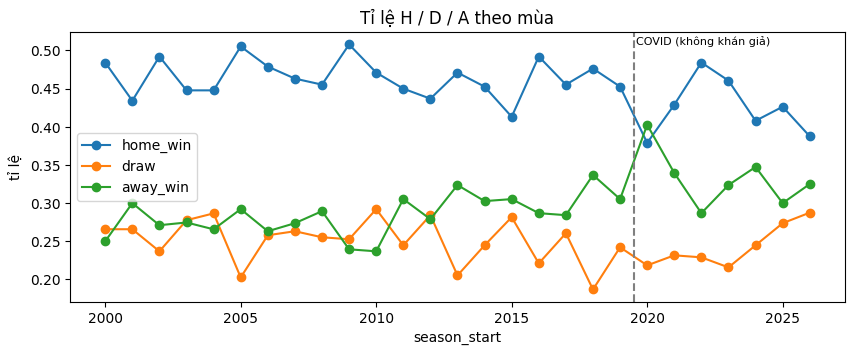

In [ ]:
played_all = df[df['status'].eq('played')].dropna(subset=['result', 'home_goals', 'away_goals']).copy()
print('Phân bố nhãn (toàn bộ trận đã đá):')
print(played_all['result'].value_counts(normalize=True).round(3))
print('\nBàn thắng TB  nhà: %.3f | khách: %.3f' % (played_all.home_goals.mean(), played_all.away_goals.mean()))

miss = df.isna().mean().sort_values(ascending=False)
print('\n20 cột thiếu dữ liệu nhiều nhất:')
print(miss.head(20).round(3).to_string())

# Lợi thế sân nhà theo mùa (liên quan H5)
ha = played_all.groupby('season_start').agg(home_win=('result', lambda r: (r == 'H').mean()),
                                            draw=('result', lambda r: (r == 'D').mean()),
                                            away_win=('result', lambda r: (r == 'A').mean()))
ha.plot(figsize=(10, 3.5), marker='o', title='Tỉ lệ H / D / A theo mùa')
plt.axvline(2019.5, ls='--', c='grey'); plt.text(2019.6, ha.values.max(), 'COVID (không khán giả)', fontsize=8)
plt.ylabel('tỉ lệ'); plt.show()

## 2. Chia Train / Dev / Test theo mùa

In [ ]:
def split_name(y):
    if TRAIN_START <= y <= TRAIN_END: return 'train'
    if DEV_START <= y <= DEV_END:     return 'dev'
    if y >= TEST_START:               return 'test'
    return 'unused'

played_all['split'] = played_all['season_start'].map(split_name)
upcoming = df[df['status'].eq('upcoming')].copy()

train = played_all[played_all.split == 'train'].copy()
dev   = played_all[played_all.split == 'dev'].copy()
test  = played_all[played_all.split == 'test'].copy()

summary = played_all.groupby('split').agg(n=('result', 'size'),
                                          mua_dau=('season', 'first'), mua_cuoi=('season', 'last'),
                                          H=('result', lambda r: (r == 'H').mean()),
                                          D=('result', lambda r: (r == 'D').mean()),
                                          A=('result', lambda r: (r == 'A').mean()))
print(summary.reindex(['train', 'dev', 'test', 'unused']).dropna(how='all').round(3).to_string())
print('Trận upcoming:', len(upcoming))

# Kiểm tra thứ tự thời gian: không dùng tương lai đoán quá khứ
if DATE_COL:
    assert train[DATE_COL].max() < dev[DATE_COL].min() <= dev[DATE_COL].max() < test[DATE_COL].min(), 'Các tập chồng lấn thời gian!'
    print('OK: train < dev < test theo thời gian.')

            n  mua_dau mua_cuoi      H      D      A
split                                               
train  8270.0  2000/01  2021/22  0.459  0.249  0.292
dev     760.0  2022/23  2023/24  0.472  0.222  0.305
test    840.0  2024/25  2026/27  0.414  0.262  0.324
Trận upcoming: 0
OK: train < dev < test theo thời gian.


## 3. Chọn cột đặc trưng + kiểm tra rò rỉ dữ liệu
Loại: cột ID / tên đội / ngày / mùa, nhãn (`home_goals`, `away_goals`, `result`), và **odds** (trận sắp đá chưa có odds).
Sau đó quét các cột còn lại: cột nào tương quan quá mạnh với hiệu số bàn thắng **của chính trận đó** thì nhiều khả năng là thống kê sau trận (ví dụ xG của trận) → loại khỏi các mô hình dùng nhiều cột.

In [ ]:
RESULT_ORDER = ['H', 'D', 'A']
TARGETS = ['home_goals', 'away_goals', 'result']
ID_LIKE   = re.compile(r'(^id$|_id$|^match_?id|team|^date|datetime|kickoff|season|status|^split$|referee|venue|stadium|url|_name$|gameweek|provisional|postponed)', re.I)
META_LIKE = re.compile(r'(_window_n5$|_xg_n5$|_fm_n5$)', re.I)   # cột đếm số trận có dữ liệu: chỉ dùng để lọc, không làm đặc trưng
ODDS_LIKE = re.compile(r'(odd|b365|bet|pinn|^ps[hda]$|^avg[hda]$|^max[hda]$|implied|bookie|bookmaker|market|overround)', re.I)

num_cols = df.select_dtypes(include=[np.number]).columns
excluded = [c for c in df.columns if c in TARGETS or ID_LIKE.search(c) or ODDS_LIKE.search(c) or META_LIKE.search(c)]
CANDIDATES = [c for c in num_cols if c not in excluded]
print(f'{len(CANDIDATES)} cột số có thể dùng làm đặc trưng.')
print('Đã loại:', excluded)

# --- Kiểm tra rò rỉ: tương quan với hiệu số bàn thắng trận đó (trên train) ---
gd = train['home_goals'] - train['away_goals']
corr = train[CANDIDATES].corrwith(gd).abs().sort_values(ascending=False)
LEAK_THRESHOLD = 0.55   # elo_diff thường chỉ ~0.3–0.4
LEAKY = corr[corr > LEAK_THRESHOLD].index.tolist()
print('\nTop 10 |corr| với hiệu số bàn thắng:'); print(corr.head(10).round(3).to_string())
print('\n Nghi rò rỉ (bị loại):', LEAKY if LEAKY else 'không có')
SAFE_FEATS = [c for c in CANDIDATES if c not in LEAKY]

# --- Cột odds (chỉ dùng cho H9 làm mốc tham chiếu, KHÔNG làm đặc trưng) ---
def find_odds_triplet(cols):
    oc = [c for c in cols if ODDS_LIKE.search(c) and pd.api.types.is_numeric_dtype(df[c])]
    pick = lambda pats: next((c for c in oc for p in pats if re.search(p, c, re.I)), None)
    h = pick([r'home', r'_h$', r'^b365h$', r'^psh$', r'^avgh$'])
    d = pick([r'draw', r'_d$', r'^b365d$', r'^psd$', r'^avgd$'])
    a = pick([r'away', r'_a$', r'^b365a$', r'^psa$', r'^avga$'])
    return (h, d, a) if all([h, d, a]) and len({h, d, a}) == 3 else None

ODDS_COLS = find_odds_triplet(df.columns)   # sửa tay nếu tự dò sai, ví dụ ('B365H','B365D','B365A')
print('\nCột odds:', ODDS_COLS)

# --- Đặc trưng từ odds (chỉ đưa vào mô hình khi USE_ODDS_FEATURE = True) ---
ODDS_IS_PROB = ODDS_COLS is not None and np.nanmax(df[list(ODDS_COLS)].astype(float).values) <= 1.0

def odds_probs(d):
    O = d[list(ODDS_COLS)].astype(float).values
    Q = O if ODDS_IS_PROB else 1.0 / O
    Q = np.where(Q > 0, Q, np.nan)
    return Q / Q.sum(1, keepdims=True)            # bỏ overround: chuẩn hóa tổng = 1

def add_odds_features(d):
    if ODDS_COLS is None: return d
    P = odds_probs(d)
    with np.errstate(divide='ignore', invalid='ignore'):
        d['odds_logit_ha'] = np.log(P[:, 0] / P[:, 2])   # >0: nhà cái nghiêng đội nhà
        d['odds_log_d'] = np.log(P[:, 1])                 # khả năng hòa theo nhà cái
    ok = np.isfinite(d['odds_logit_ha']) & np.isfinite(d['odds_log_d'])
    d.loc[~ok, ['odds_logit_ha', 'odds_log_d']] = np.nan  # để Imputer điền trung vị
    d['odds_missing'] = (~ok).astype(float)
    return d

for _d in (df, played_all, train, dev, test, upcoming):
    add_odds_features(_d)

ODDS_FEATS = ['odds_logit_ha', 'odds_log_d', 'odds_missing'] if (USE_ODDS_FEATURE and ODDS_COLS is not None) else []
if USE_ODDS_FEATURE and ODDS_COLS is None:
    print('USE_ODDS_FEATURE = True nhưng không tìm thấy cột odds → train KHÔNG có odds.')
if ODDS_FEATS:
    print('✅ Odds được dùng làm đặc trưng:', ODDS_FEATS)
    print('   Tỉ lệ trận có odds — train: %.1f%% | dev: %.1f%% | test: %.1f%%'
          % tuple(100 * (1 - d['odds_missing'].mean()) for d in (train, dev, test)))

87 cột số có thể dùng làm đặc trưng.
Đã loại: ['match_id', 'season', 'date', 'kickoff_time', 'gameweek', 'home_club_id', 'home_team', 'away_club_id', 'away_team', 'status', 'provisional', 'postponed', 'home_window_n5', 'home_xg_n5', 'home_fm_n5', 'away_window_n5', 'away_xg_n5', 'away_fm_n5', 'odds_home_prob', 'odds_draw_prob', 'odds_away_prob', 'home_goals', 'away_goals', 'result', 'season_start']

Top 10 |corr| với hiệu số bàn thắng:
elo_diff                 0.441
elo_home_win_prob        0.439
diff_xg5                 0.359
position_diff            0.358
diff_possession5         0.345
diff_ppg                 0.342
diff_box_touches5        0.341
home_elo                 0.324
diff_shots_on_target5    0.314
away_elo                 0.310

⚠️  Nghi rò rỉ (bị loại): không có

Cột odds: ('odds_home_prob', 'odds_draw_prob', 'odds_away_prob')


In [ ]:
def have(cols, label=''):
    present = [c for c in cols if c in df.columns]
    missing = [c for c in cols if c not in df.columns]
    if missing: print(f' [{label}] thiếu cột: {missing}')
    return present

# Theo PDF
LR_BASE  = have(['elo_diff', 'diff_points5', 'diff_goals_for5', 'diff_goals_against5', 'diff_ppg', 'position_diff'], 'LR 6 cột') + ODDS_FEATS
POI_FEATS = have(['elo_diff', 'home_goals_for5', 'home_goals_against5', 'away_goals_for5', 'away_goals_against5',
                  'home_home_goals_for5', 'away_away_goals_against5', 'diff_xg5', 'diff_xga5'], 'Poisson') + ODDS_FEATS
ODDS_TAG = ' + odds' if ODDS_FEATS else ''
N_M2, N_M3 = f'M2 LR 6 cột{ODDS_TAG}', f'M3 LR 6 + lam_diff{ODDS_TAG}'   # tên mô hình hiển thị
print('LR_BASE :', LR_BASE)
print('POI_FEATS:', POI_FEATS)

LR_BASE : ['elo_diff', 'diff_points5', 'diff_goals_for5', 'diff_goals_against5', 'diff_ppg', 'position_diff']
POI_FEATS: ['elo_diff', 'home_goals_for5', 'home_goals_against5', 'away_goals_for5', 'away_goals_against5', 'home_home_goals_for5', 'away_away_goals_against5', 'diff_xg5', 'diff_xga5']


## 4. Tiền xử lý & hàm đánh giá

In [ ]:
class ClipPercentile(BaseEstimator, TransformerMixin):
    # Cắt mỗi cột về [phân vị lower, phân vị upper] học từ tập fit (train).
    def __init__(self, lower=1.0, upper=99.0):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanpercentile(X, self.lower, axis=0)
        self.hi_ = np.nanpercentile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_prep():
    return [('imp', SimpleImputer(strategy='median')),
            ('clip', ClipPercentile(1, 99)),
            ('sc', StandardScaler())]

def lr_pipe(C):
    return Pipeline(make_prep() + [('lr', LogisticRegression(C=C, max_iter=5000))])

def proba_HDA(model, X):
    # predict_proba trả theo model.classes_ = ['A','D','H'] → sắp lại thành H, D, A
    P = model.predict_proba(X)
    cls = list(model.classes_)
    return P[:, [cls.index(k) for k in RESULT_ORDER]]

def onehot(y):
    y = np.asarray(y)
    return np.stack([(y == k) for k in RESULT_ORDER], axis=1).astype(float)

def ll_vec(P, y):   # log loss từng trận
    return -np.log(np.clip((P * onehot(y)).sum(1), 1e-15, 1))

def rps_vec(P, y):  # Ranked Probability Score từng trận (thứ tự H < D < A)
    cP = np.cumsum(P, 1)[:, :2]; cY = np.cumsum(onehot(y), 1)[:, :2]
    return ((cP - cY) ** 2).sum(1) / 2

def evaluate(P, y, name=''):
    y = np.asarray(y)
    return {'model': name, 'n': len(y),
            'log_loss': ll_vec(P, y).mean(),
            'rps': rps_vec(P, y).mean(),
            'brier': ((P - onehot(y)) ** 2).sum(1).mean(),
            'accuracy': (np.array(RESULT_ORDER)[P.argmax(1)] == y).mean()}

def paired_bootstrap(loss_base, loss_new, B=2000, seed=SEED):
    # Δ = loss_new − loss_base (âm = mô hình mới tốt hơn). Trả về Δ, CI95%, P(Δ ≥ 0)
    d = np.asarray(loss_new) - np.asarray(loss_base)
    rng = np.random.default_rng(seed)
    boots = np.empty(B)
    for b in range(0, B, 200):                        # theo lô để tiết kiệm RAM
        idx = rng.integers(0, len(d), size=(min(200, B - b), len(d)))
        boots[b:b + idx.shape[0]] = d[idx].mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return d.mean(), lo, hi, (boots >= 0).mean()

def bookie_probs(data):
    if ODDS_COLS is None: return None
    return odds_probs(data)   # features.csv lưu sẵn xác suất (odds_*_prob); odds thập phân thì đổi 1/odds

## 5. Nhiệm vụ 2 — Poisson (λ nhà, λ khách) + Dixon–Coles
- Dò `alpha ∈ {0.01, 0.1, 1}` theo MAE trên Dev (như PDF).
- `lam_diff` cho train: **out-of-fold theo mùa** (mỗi mùa được dự đoán bởi mô hình không thấy mùa đó).
- Dixon–Coles: ước lượng một tham số ρ trên train để chỉnh xác suất 0-0, 1-0, 0-1, 1-1.

In [ ]:
ALPHAS = [0.01, 0.1, 1.0]
MAX_GOALS = 10

def poisson_pipe(alpha):
    return Pipeline(make_prep() + [('poi', PoissonRegressor(alpha=alpha, max_iter=3000))])

def fit_poisson(data, alpha):
    mh = poisson_pipe(alpha).fit(data[POI_FEATS], data['home_goals'])
    ma = poisson_pipe(alpha).fit(data[POI_FEATS], data['away_goals'])
    return mh, ma

def predict_lams(models, data):
    mh, ma = models
    return mh.predict(data[POI_FEATS]), ma.predict(data[POI_FEATS])

def oof_lams(data, alpha, n_splits=5):
    lh = np.full(len(data), np.nan); la = np.full(len(data), np.nan)
    groups = data['season_start'].values
    gkf = GroupKFold(n_splits=min(n_splits, len(np.unique(groups))))
    for tr_idx, va_idx in gkf.split(data, groups=groups):
        m = fit_poisson(data.iloc[tr_idx], alpha)
        lh[va_idx], la[va_idx] = predict_lams(m, data.iloc[va_idx])
    return lh, la

def score_matrix(lh, la, rho=0.0):
    lh = np.asarray(lh, float); la = np.asarray(la, float)
    g = np.arange(MAX_GOALS + 1)
    M = poisson.pmf(g[None, :, None], lh[:, None, None]) * poisson.pmf(g[None, None, :], la[:, None, None])
    if rho != 0.0:   # hệ số tau của Dixon–Coles; M[:, bàn nhà, bàn khách]
        M[:, 0, 0] *= 1 - lh * la * rho
        M[:, 0, 1] *= 1 + lh * rho
        M[:, 1, 0] *= 1 + la * rho
        M[:, 1, 1] *= 1 - rho
    M = np.clip(M, 1e-12, None)
    return M / M.sum(axis=(1, 2), keepdims=True)

_I, _J = np.meshgrid(np.arange(MAX_GOALS + 1), np.arange(MAX_GOALS + 1), indexing='ij')
REGION = {'H': _I > _J, 'D': _I == _J, 'A': _I < _J}

def matrix_to_hda(M):
    return np.stack([M[:, REGION[k]].sum(1) for k in RESULT_ORDER], axis=1)

def fit_rho(lh, la, hg, ag):
    hg = np.clip(np.asarray(hg, int), 0, MAX_GOALS); ag = np.clip(np.asarray(ag, int), 0, MAX_GOALS)
    def nll(rho):
        M = score_matrix(lh, la, rho)
        return -np.log(M[np.arange(len(hg)), hg, ag]).sum()
    return minimize_scalar(nll, bounds=(-0.25, 0.25), method='bounded').x

# --- Dò alpha trên Dev ---
rows = []
for a in ALPHAS:
    m = fit_poisson(train, a)
    lh, la = predict_lams(m, dev)
    rows.append({'alpha': a,
                 'MAE_home': mean_absolute_error(dev.home_goals, lh),
                 'MAE_away': mean_absolute_error(dev.away_goals, la)})
alpha_tab = pd.DataFrame(rows); alpha_tab['MAE_avg'] = alpha_tab[['MAE_home', 'MAE_away']].mean(1)
print(alpha_tab.round(4).to_string(index=False))
BEST_ALPHA = float(alpha_tab.loc[alpha_tab.MAE_avg.idxmin(), 'alpha'])
print('→ alpha tốt nhất:', BEST_ALPHA)

 alpha  MAE_home  MAE_away  MAE_avg
  0.01    1.0022    0.9155   0.9588
  0.10    1.0038    0.9144   0.9591
  1.00    1.0172    0.9124   0.9648
→ alpha tốt nhất: 0.01


In [ ]:
def prepare_stage(tr, te_list, alpha):
    # Thêm lam_h, lam_a, lam_diff: tr dùng out-of-fold, các tập te dùng mô hình fit trên toàn tr.
    tr = tr.copy()
    tr['lam_h'], tr['lam_a'] = oof_lams(tr, alpha)
    models = fit_poisson(tr, alpha)
    outs = []
    for te in te_list:
        te = te.copy()
        if len(te):
            te['lam_h'], te['lam_a'] = predict_lams(models, te)
        else:
            te['lam_h'] = te['lam_a'] = np.array([], float)
        outs.append(te)
    for d in [tr] + outs:
        d['lam_diff'] = d['lam_h'] - d['lam_a']
    rho = fit_rho(tr.lam_h, tr.lam_a, tr.home_goals, tr.away_goals)
    return tr, outs, models, rho

tr_s, (dev_s,), poi_models_sel, RHO_SEL = prepare_stage(train, [dev], BEST_ALPHA)
print(f'ρ Dixon–Coles (train) = {RHO_SEL:.4f}')

# So sánh lam_diff in-sample (cách làm "ngây thơ") với out-of-fold
lh_in, la_in = predict_lams(poi_models_sel, tr_s)
print('corr(lam_diff, hiệu số) trên train — in-sample: %.3f | out-of-fold: %.3f'
      % (np.corrcoef(lh_in - la_in, tr_s.home_goals - tr_s.away_goals)[0, 1],
         np.corrcoef(tr_s.lam_diff, tr_s.home_goals - tr_s.away_goals)[0, 1]))

# Chất lượng tỉ số trên Dev
for rho_name, rho in [('Poisson độc lập', 0.0), ('Dixon–Coles', RHO_SEL)]:
    M = score_matrix(dev_s.lam_h, dev_s.lam_a, rho)
    hg = np.clip(dev_s.home_goals.astype(int), 0, MAX_GOALS).values
    ag = np.clip(dev_s.away_goals.astype(int), 0, MAX_GOALS).values
    p_true = M[np.arange(len(hg)), hg, ag]
    flat = M.reshape(len(M), -1).argmax(1)
    exact = ((flat // (MAX_GOALS + 1) == hg) & (flat % (MAX_GOALS + 1) == ag)).mean()
    P = matrix_to_hda(M)
    print(f'{rho_name:16s} | score log-lik/trận: {np.log(p_true).mean():.4f} | đúng tỉ số: {exact:.3f} '
          f'| P(D) TB: {P[:,1].mean():.3f} (thực tế {np.mean(dev_s.result=="D"):.3f}) '
          f'| H/D/A log loss: {ll_vec(P, dev_s.result).mean():.4f}')

ρ Dixon–Coles (train) = -0.0389
corr(lam_diff, hiệu số) trên train — in-sample: 0.443 | out-of-fold: 0.440
Poisson độc lập  | score log-lik/trận: -3.0550 | đúng tỉ số: 0.118 | P(D) TB: 0.227 (thực tế 0.222) | H/D/A log loss: 0.9508
Dixon–Coles      | score log-lik/trận: -3.0556 | đúng tỉ số: 0.112 | P(D) TB: 0.235 (thực tế 0.222) | H/D/A log loss: 0.9512


## 6. Nhiệm vụ 1 — Logistic Regression H/D/A (theo PDF)
Dò `C ∈ {0.01, 0.03, 0.1, 0.3, 1}` theo log loss trên Dev, cho 6 cột và 6 cột + `lam_diff`.

In [ ]:
C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0]

def fit_predict(spec, tr, te, rho):
    # Huấn luyện mô hình theo spec trên tr, trả (xác suất H/D/A trên te, model)
    k = spec['kind']
    if k == 'prior':
        p = tr['result'].value_counts(normalize=True).reindex(RESULT_ORDER).fillna(0).values
        return np.tile(p, (len(te), 1)), None
    if k == 'lr':
        m = lr_pipe(spec['C']).fit(tr[spec['feats']], tr['result'])
        return proba_HDA(m, te[spec['feats']]), m
    if k == 'dc':
        return matrix_to_hda(score_matrix(te.lam_h, te.lam_a, rho)), None
    if k == 'hgb':
        m = HistGradientBoostingClassifier(learning_rate=spec['lr'], max_depth=spec['depth'], max_iter=1000,
                                           min_samples_leaf=50, l2_regularization=1.0, early_stopping=True,
                                           validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
        feats = [c for c in spec['feats'] if tr[c].nunique(dropna=True) >= 2]   # bỏ cột hằng / toàn NaN
        m.fit(tr[feats], tr['result'])
        return proba_HDA(m, te[feats]), m
    if k == 'blend':
        P1, m1 = fit_predict(spec['a'], tr, te, rho)
        P2, _ = fit_predict(spec['b'], tr, te, rho)
        return spec['w'] * P1 + (1 - spec['w']) * P2, m1
    raise ValueError(k)

def tune_lr(feats, label):
    res = []
    for C in C_GRID:
        P, _ = fit_predict({'kind': 'lr', 'feats': feats, 'C': C}, tr_s, dev_s, RHO_SEL)
        res.append({'feature_set': label, 'C': C, **{k: v for k, v in evaluate(P, dev_s.result).items() if k not in ('model', 'n')}})
    res = pd.DataFrame(res)
    best = res.loc[res.log_loss.idxmin()]
    return res, float(best.C)

tab6, C6 = tune_lr(LR_BASE, '6 cột')
tab7, C7 = tune_lr(LR_BASE + ['lam_diff'], '6 cột + lam_diff')
print(pd.concat([tab6, tab7]).round(4).to_string(index=False))
print(f'\n→ C tốt nhất: 6 cột = {C6}, 6 cột + lam_diff = {C7}')

     feature_set    C  log_loss    rps  brier  accuracy
           6 cột 0.01    0.9534 0.1964 0.5648    0.5539
           6 cột 0.03    0.9543 0.1967 0.5653    0.5526
           6 cột 0.10    0.9549 0.1969 0.5657    0.5513
           6 cột 0.30    0.9552 0.1969 0.5658    0.5500
           6 cột 1.00    0.9552 0.1969 0.5658    0.5500
6 cột + lam_diff 0.01    0.9526 0.1961 0.5641    0.5553
6 cột + lam_diff 0.03    0.9535 0.1964 0.5646    0.5539
6 cột + lam_diff 0.10    0.9539 0.1965 0.5648    0.5526
6 cột + lam_diff 0.30    0.9541 0.1966 0.5649    0.5539
6 cột + lam_diff 1.00    0.9542 0.1966 0.5650    0.5553

→ C tốt nhất: 6 cột = 0.01, 6 cột + lam_diff = 0.01


## 7. Nhiệm vụ 3 — Kiểm định giả thuyết H1–H9
Mỗi giả thuyết: **mô hình gốc** vs **mô hình gốc + nhóm đặc trưng**, cùng một tập trận.
Đánh giá bằng *rolling-origin*: với mỗi mùa 2015/16 → 2023/24, huấn luyện trên **tất cả mùa trước đó**, dự đoán mùa đó. Không dùng Test.
Δ = log loss(có nhóm) − log loss(không có nhóm): **Δ < 0 và CI95% nằm hẳn dưới 0 → nhóm đặc trưng có ích.**

> Tên cột của H4, H7, H8 được dò bằng regex từ tên cột. Hãy xem bảng in ra; nếu dò sai, sửa trực tiếp danh sách `add` trong `HYPOTHESES`.

In [ ]:
if os.path.exists(HYP_CSV):
    hyp_file = pd.read_csv(HYP_CSV)
    print('hypotheses.csv:'); display(hyp_file) if 'display' in globals() else print(hyp_file.to_string())
else:
    print('Không thấy', HYP_CSV, '→ dùng định nghĩa nhóm cột bên dưới.')

def rx(pattern, exclude=()):
    return [c for c in SAFE_FEATS if re.search(pattern, c, re.I) and c not in exclude]

ELO  = have(['elo_diff'], 'H')
FORM = have(['diff_points5', 'diff_goals_for5', 'diff_goals_against5', 'diff_ppg', 'position_diff'], 'H2')
GOALS_SIDE = have(['home_goals_for5', 'home_goals_against5', 'away_goals_for5', 'away_goals_against5'], 'H6')
FOTMOB_PATTERN = r'possession|pass_accuracy|big_chances|box_shots|box_touches|xgot'

def n5_filter(prefix):
    def f(d):
        h, a = f'home_{prefix}_n5', f'away_{prefix}_n5'
        if {h, a} <= set(d.columns):
            return (d[h] >= 3) & (d[a] >= 3)
        return pd.Series(True, index=d.index)
    return f
xg_filter, fm_filter = n5_filter('xg'), n5_filter('fm')

HYPOTHESES = {
    'H1': dict(desc='Elo tốt hơn dự đoán theo tần suất nhãn lịch sử', base='PRIOR', add=ELO),
    'H2': dict(desc='Phong độ điểm, bàn thắng/thua bổ sung ngoài Elo', base=ELO, add=FORM),
    'H3': dict(desc='Phong độ xG / xGA bổ sung ngoài bàn thắng', base=ELO + FORM,
               add=have(['diff_xg5', 'diff_xga5'], 'H3'), filter=xg_filter),
    'H4': dict(desc='Đối đầu bổ sung sau khi đã có Elo và phong độ', base=ELO + FORM, add=rx(r'h2h|head_?to_?head')),
    'H5': dict(desc='Lợi thế sân nhà thay đổi theo thời kỳ', base=ELO + FORM, add=have(['league_home_adv380'], 'H5')),
    'H6': dict(desc='Phong độ đúng sân bổ sung cho phong độ tổng', base=ELO + FORM + GOALS_SIDE,
               add=rx(r'^home_home_|^away_away_')),
    'H7': dict(desc='Khoảng nghỉ định nghĩa đúng có ích', base=ELO + FORM,
               add=rx(r'_promoted$|_form_age_days$|_rest_days$')),
    'H8': dict(desc='Chỉ số lối chơi FotMob bổ sung thông tin', base=ELO + FORM,
               add=[c for c in rx(FOTMOB_PATTERN) if c.startswith('diff_')] or rx(FOTMOB_PATTERN), filter=fm_filter),
}
if ODDS_FEATS:   # kiểm định thêm: odds có bổ sung thông tin ngoài Elo + phong độ không
    HYPOTHESES['H10'] = dict(desc='Odds nhà cái bổ sung ngoài Elo + phong độ', base=ELO + FORM, add=ODDS_FEATS)
for h, s in HYPOTHESES.items():
    print(f"{h}: +{len(s['add'])} cột → {s['add'][:12]}{' ...' if len(s['add']) > 12 else ''}")

Không thấy /content/drive/MyDrive/datasets/epl--league-dataset/EDA/reports/eda_matches_features/hypotheses.csv → dùng định nghĩa nhóm cột bên dưới.
H1: +1 cột → ['elo_diff']
H2: +5 cột → ['diff_points5', 'diff_goals_for5', 'diff_goals_against5', 'diff_ppg', 'position_diff']
H3: +2 cột → ['diff_xg5', 'diff_xga5']
H4: +3 cột → ['h2h_matches', 'h2h_home_points', 'h2h_home_goal_diff']
H5: +1 cột → ['league_home_adv380']
H6: +6 cột → ['home_home_points5', 'home_home_goals_for5', 'home_home_goals_against5', 'away_away_points5', 'away_away_goals_for5', 'away_away_goals_against5']
H7: +6 cột → ['home_rest_days', 'home_form_age_days', 'home_promoted', 'away_rest_days', 'away_form_age_days', 'away_promoted']
H8: +6 cột → ['diff_possession5', 'diff_big_chances5', 'diff_big_chances_against5', 'diff_box_touches5', 'diff_xgot5', 'diff_xgot_against5']


In [ ]:
PRE_TEST = played_all[played_all.season_start < TEST_START].copy()
EVAL_SEASONS = list(range(2015, TEST_START))   # 2015/16 → 2023/24
C_HYP = C6                                     # dùng C đã chọn cho LR 6 cột

def rolling_origin(data, feats, C=C_HYP):
    Ps, ys, idx = [], [], []
    for s in EVAL_SEASONS:
        tr = data[data.season_start < s]; te = data[data.season_start == s]
        if len(te) == 0 or len(tr) < 300: continue
        spec = {'kind': 'prior'} if feats == 'PRIOR' else {'kind': 'lr', 'feats': feats, 'C': C}
        P, _ = fit_predict(spec, tr, te, 0.0)
        Ps.append(P); ys.append(te.result.values); idx.append(te.index.values)
    return np.vstack(Ps), np.concatenate(ys), np.concatenate(idx)

hyp_rows = []
for h, s in HYPOTHESES.items():
    if not s['add']:
        hyp_rows.append({'H': h, 'giả thuyết': s['desc'], 'kết luận': 'BỎ QUA (không có cột)'}); continue
    data = PRE_TEST[s['filter'](PRE_TEST)] if 'filter' in s else PRE_TEST
    if data[data.season_start.isin(EVAL_SEASONS)].shape[0] < 300:
        hyp_rows.append({'H': h, 'giả thuyết': s['desc'], 'kết luận': 'BỎ QUA (quá ít trận đủ dữ liệu)'}); continue
    base_feats = s['base']
    new_feats = s['add'] if base_feats == 'PRIOR' else list(dict.fromkeys(base_feats + s['add']))
    P0, y, _ = rolling_origin(data, base_feats)
    P1, _, _ = rolling_origin(data, new_feats)
    l0, l1 = ll_vec(P0, y), ll_vec(P1, y)
    d, lo, hi, p = paired_bootstrap(l0, l1)
    verdict = 'CÓ ÍCH' if hi < 0 else ('CÓ HẠI' if lo > 0 else 'chưa đủ bằng chứng')
    hyp_rows.append({'H': h, 'giả thuyết': s['desc'], 'n_trận': len(y), 'n_cột_thêm': len(s['add']),
                     'mùa_đánh_giá': f"{int(data.loc[data.season_start.isin(EVAL_SEASONS), 'season_start'].min())}→2023",
                     'LL_gốc': l0.mean(), 'LL_mới': l1.mean(), 'Δ': d, 'CI_low': lo, 'CI_high': hi,
                     'P(Δ≥0)': p, 'kết luận': verdict})

# H9 — kèo nhà cái làm mốc tham chiếu (so với LR 6 cột, cùng tập trận có odds)
if ODDS_COLS is not None:
    Pm, y, idx = rolling_origin(PRE_TEST, LR_BASE)
    Pb = bookie_probs(PRE_TEST.loc[idx])
    ok = np.isfinite(Pb).all(1)
    lb, lm = ll_vec(Pb[ok], y[ok]), ll_vec(Pm[ok], y[ok])
    d, lo, hi, p = paired_bootstrap(lb, lm)
    hyp_rows.append({'H': 'H9', 'giả thuyết': 'Kèo nhà cái làm mốc tham chiếu (Δ = LR − nhà cái)', 'n_trận': int(ok.sum()),
                     'LL_gốc': lb.mean(), 'LL_mới': lm.mean(), 'Δ': d, 'CI_low': lo, 'CI_high': hi, 'P(Δ≥0)': p,
                     'kết luận': 'nhà cái tốt hơn mô hình' if lo > 0 else ('mô hình ≥ nhà cái' if hi < 0 else 'tương đương')})
else:
    hyp_rows.append({'H': 'H9', 'giả thuyết': 'Kèo nhà cái làm mốc tham chiếu', 'kết luận': 'BỎ QUA (không có cột odds)'})

hyp_res = pd.DataFrame(hyp_rows)
print(hyp_res.round(4).to_string(index=False))
hyp_res.to_csv(os.path.join(OUT_DIR, 'hypothesis_tests.csv'), index=False)

 H                                        giả thuyết  n_trận  n_cột_thêm mùa_đánh_giá  LL_gốc  LL_mới       Δ  CI_low  CI_high  P(Δ≥0)                kết luận
H1    Elo tốt hơn dự đoán theo tần suất nhãn lịch sử    3420         1.0    2015→2023  1.0660  0.9712 -0.0947 -0.1079  -0.0818  0.0000                  CÓ ÍCH
H2   Phong độ điểm, bàn thắng/thua bổ sung ngoài Elo    3420         5.0    2015→2023  0.9712  0.9697 -0.0015 -0.0028  -0.0001  0.0180                  CÓ ÍCH
H3         Phong độ xG / xGA bổ sung ngoài bàn thắng    3378         2.0    2015→2023  0.9756  0.9724 -0.0032 -0.0059  -0.0003  0.0125                  CÓ ÍCH
H4     Đối đầu bổ sung sau khi đã có Elo và phong độ    3420         3.0    2015→2023  0.9697  0.9700  0.0002 -0.0010   0.0015  0.6380      chưa đủ bằng chứng
H5             Lợi thế sân nhà thay đổi theo thời kỳ    3420         1.0    2015→2023  0.9697  0.9690 -0.0007 -0.0022   0.0009  0.1790      chưa đủ bằng chứng
H6       Phong độ đúng sân bổ sung cho phong đ

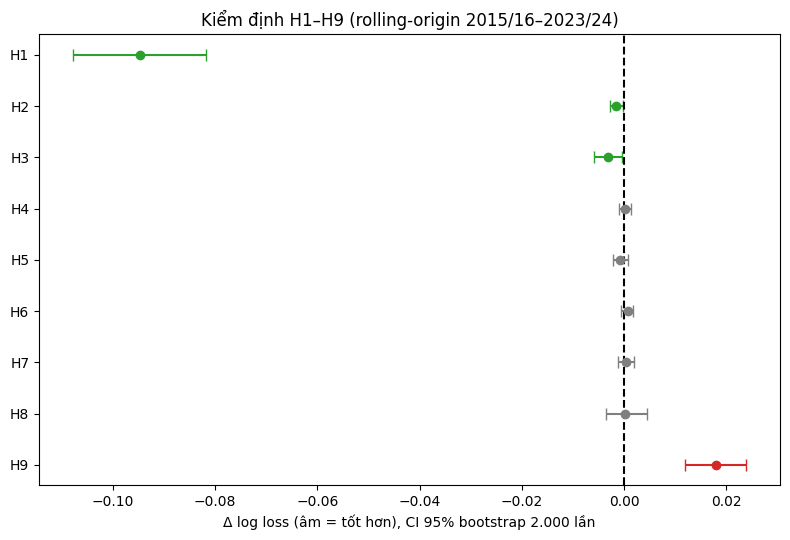

In [ ]:
pl = hyp_res.dropna(subset=['Δ'])
fig, ax = plt.subplots(figsize=(8, 0.5 * len(pl) + 1))
colors = ['tab:green' if h < 0 else ('tab:red' if l > 0 else 'tab:grey') for l, h in zip(pl.CI_low, pl.CI_high)]
for k, (dm, l, h, col) in enumerate(zip(pl['Δ'], pl.CI_low, pl.CI_high, colors)):
    ax.errorbar(dm, k, xerr=[[dm - l], [h - dm]], fmt='o', color=col, capsize=4)
ax.axvline(0, ls='--', c='k'); ax.set_yticks(range(len(pl))); ax.set_yticklabels(pl['H']); ax.invert_yaxis()
ax.set_xlabel('Δ log loss (âm = tốt hơn), CI 95% bootstrap 2.000 lần'); ax.set_title('Kiểm định H1–H9 (rolling-origin 2015/16–2023/24)')
plt.tight_layout(); plt.show()

## 8. Mô hình nâng cấp & so sánh trên Dev
- **M0** tần suất · **M1** LR chỉ Elo · **M2** LR 6 cột · **M3** LR 6 cột + `lam_diff` (mô hình PDF)
- **M4** Dixon–Coles (xác suất H/D/A suy từ ma trận tỉ số)
- **M5** LR+ = M3 + các nhóm đặc trưng được kiểm định **CÓ ÍCH** ở mục 7
- **M6** HistGradientBoosting (learning rate nhỏ, cây nông, early stopping) trên toàn bộ cột an toàn
- **M7** Blend: w·(LR tốt nhất) + (1−w)·Dixon–Coles, w chọn trên Dev

In [ ]:
accepted = [c for h, s in HYPOTHESES.items() if h != 'H1'
            for c in s['add'] if (hyp_res.set_index('H').loc[h, 'kết luận'] == 'CÓ ÍCH')]
LR_PLUS = list(dict.fromkeys(LR_BASE + ['lam_diff'] + accepted))
print('Cột thêm cho LR+ :', accepted if accepted else '(không có nhóm nào qua kiểm định → LR+ = M3)')
tab_plus, C_PLUS = tune_lr(LR_PLUS, 'LR+')
print(tab_plus.round(4).to_string(index=False))

HGB_FEATS = list(dict.fromkeys(SAFE_FEATS + ['lam_diff'] + ODDS_FEATS))
hgb_rows = []
for lr_ in [0.02, 0.05]:
    for depth in [2, 3]:
        P, _ = fit_predict({'kind': 'hgb', 'feats': HGB_FEATS, 'lr': lr_, 'depth': depth}, tr_s, dev_s, RHO_SEL)
        hgb_rows.append({'lr': lr_, 'depth': depth, **evaluate(P, dev_s.result)})
hgb_tab = pd.DataFrame(hgb_rows); print('\nHGB:'); print(hgb_tab.drop(columns=['model', 'n']).round(4).to_string(index=False))
best_hgb = hgb_tab.loc[hgb_tab.log_loss.idxmin()]

SPECS = {
    'M0 Tần suất':          {'kind': 'prior'},
    'M1 LR Elo':            {'kind': 'lr', 'feats': ELO, 'C': C6},
    N_M2:          {'kind': 'lr', 'feats': LR_BASE, 'C': C6},
    N_M3:   {'kind': 'lr', 'feats': LR_BASE + ['lam_diff'], 'C': C7},
    'M4 Dixon–Coles':       {'kind': 'dc'},
    'M5 LR+':               {'kind': 'lr', 'feats': LR_PLUS, 'C': C_PLUS},
    'M6 HistGB':            {'kind': 'hgb', 'feats': HGB_FEATS, 'lr': float(best_hgb.lr), 'depth': int(best_hgb.depth)},
}
dev_preds = {name: fit_predict(spec, tr_s, dev_s, RHO_SEL)[0] for name, spec in SPECS.items()}

# Blend: LR tốt nhất (M3 hoặc M5) với Dixon–Coles
lr_best_name = min([N_M3, 'M5 LR+'], key=lambda n: ll_vec(dev_preds[n], dev_s.result).mean())
ws = np.round(np.arange(0, 1.01, 0.05), 2)
blend_ll = [ll_vec(w * dev_preds[lr_best_name] + (1 - w) * dev_preds['M4 Dixon–Coles'], dev_s.result).mean() for w in ws]
W_BEST = float(ws[int(np.argmin(blend_ll))])
SPECS['M7 Blend'] = {'kind': 'blend', 'a': SPECS[lr_best_name], 'b': SPECS['M4 Dixon–Coles'], 'w': W_BEST}
dev_preds['M7 Blend'] = W_BEST * dev_preds[lr_best_name] + (1 - W_BEST) * dev_preds['M4 Dixon–Coles']
print(f'\nBlend: {lr_best_name} × w={W_BEST} + Dixon–Coles × {1-W_BEST:.2f}')

dev_board = pd.DataFrame([evaluate(P, dev_s.result, n) for n, P in dev_preds.items()]).sort_values('log_loss')

# Kiểm tra "đẹp bất thường": dự đoán EPL không dùng odds thực tế khó xuống dưới ~0.93 log loss.
# Điểm thấp hơn nhiều gần như chắc chắn là rò rỉ dữ liệu (cột sau trận, trận trùng lặp giữa các tập...).
SUSPICIOUS_LL = 0.90
sus = dev_board[dev_board.log_loss < SUSPICIOUS_LL]['model'].tolist()
if sus:
    print(f' NGHI RÒ RỈ: {sus} có log loss < {SUSPICIOUS_LL} → bị loại khỏi lựa chọn. Hãy kiểm tra lại các cột đặc trưng!')
dev_board['nghi_ro_ri'] = dev_board['model'].isin(sus)
if ODDS_COLS is not None:
    Pb = bookie_probs(dev_s); ok = np.isfinite(Pb).all(1)
    print(f'(Tham chiếu) Nhà cái trên Dev: log loss = {ll_vec(Pb[ok], dev_s.result.values[ok]).mean():.4f}')
print('\n=== BẢNG XẾP HẠNG TRÊN DEV ===')
print(dev_board.round(4).to_string(index=False))

Cột thêm cho LR+ : ['diff_points5', 'diff_goals_for5', 'diff_goals_against5', 'diff_ppg', 'position_diff', 'diff_xg5', 'diff_xga5']
feature_set    C  log_loss    rps  brier  accuracy
        LR+ 0.01    0.9526 0.1960 0.5640    0.5553
        LR+ 0.03    0.9537 0.1963 0.5646    0.5526
        LR+ 0.10    0.9541 0.1964 0.5649    0.5513
        LR+ 0.30    0.9542 0.1964 0.5650    0.5539
        LR+ 1.00    0.9544 0.1964 0.5651    0.5566

HGB:
  lr  depth  log_loss    rps  brier  accuracy
0.02      2    0.9597 0.1969 0.5679    0.5605
0.02      3    0.9661 0.1981 0.5717    0.5592
0.05      2    0.9632 0.1973 0.5698    0.5553
0.05      3    0.9695 0.1983 0.5731    0.5461

Blend: M3 LR 6 + lam_diff × w=0.25 + Dixon–Coles × 0.75
(Tham chiếu) Nhà cái trên Dev: log loss = 0.9375

=== BẢNG XẾP HẠNG TRÊN DEV ===
             model   n  log_loss    rps  brier  accuracy  nghi_ro_ri
          M7 Blend 760    0.9511 0.1956 0.5632    0.5539       False
    M4 Dixon–Coles 760    0.9512 0.1956 0.5633    

## 9. Chọn mô hình cuối cùng trên Dev

Tốt nhất trên Dev: M7 Blend
So với mô hình PDF (M3 LR 6 + lam_diff): Δ log loss = -0.0015  CI95% [-0.0054, +0.0023]
CI chứa 0 → cải thiện chưa chắc chắn → giữ mô hình PDF.
==> Mô hình cuối cùng: M3 LR 6 + lam_diff


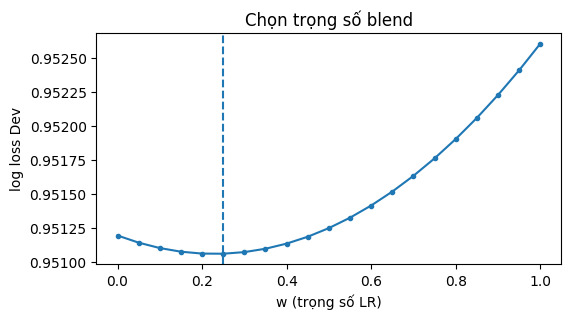

In [ ]:
# True: chỉ thay mô hình PDF (M3) khi mô hình tốt nhất hơn M3 có ý nghĩa (CI95% của Δ nằm hẳn dưới 0)
PREFER_PDF_IF_NOT_SIGNIFICANT = True
REF_NAME = N_M3
best_name = dev_board[~dev_board.nghi_ro_ri].iloc[0]['model']
FINAL_NAME = best_name
print('Tốt nhất trên Dev:', best_name)
if best_name != REF_NAME:
    d, lo, hi, p = paired_bootstrap(ll_vec(dev_preds[REF_NAME], dev_s.result), ll_vec(dev_preds[best_name], dev_s.result))
    print(f'So với mô hình PDF ({REF_NAME}): Δ log loss = {d:+.4f}  CI95% [{lo:+.4f}, {hi:+.4f}]')
    if hi >= 0 and PREFER_PDF_IF_NOT_SIGNIFICANT:
        FINAL_NAME = REF_NAME
        print('CI chứa 0 → cải thiện chưa chắc chắn → giữ mô hình PDF.')
FINAL_SPEC = SPECS[FINAL_NAME]
print('==> Mô hình cuối cùng:', FINAL_NAME)

ws_plot = plt.figure(figsize=(6, 3)); plt.plot(ws, blend_ll, marker='.'); plt.axvline(W_BEST, ls='--')
plt.xlabel('w (trọng số LR)'); plt.ylabel('log loss Dev'); plt.title('Chọn trọng số blend'); plt.show()

## 10. Huấn luyện lại trên Train + Dev → đánh giá Test (một lần duy nhất)

In [ ]:
trdev = pd.concat([train, dev])
trdev_s, (test_s,), poi_models_eval, RHO_EVAL = prepare_stage(trdev, [test], BEST_ALPHA)
print(f'ρ Dixon–Coles (train+dev) = {RHO_EVAL:.4f}  | test: {len(test_s)} trận')

test_preds = {n: fit_predict(SPECS[n], trdev_s, test_s, RHO_EVAL)[0]
              for n in dict.fromkeys(['M0 Tần suất', N_M2, REF_NAME, 'M4 Dixon–Coles', best_name, FINAL_NAME])}
test_board = pd.DataFrame([evaluate(P, test_s.result, n) for n, P in test_preds.items()]).sort_values('log_loss')
if ODDS_COLS is not None:
    Pb = bookie_probs(test_s); ok = np.isfinite(Pb).all(1)
    if ok.any():
        test_board = pd.concat([test_board, pd.DataFrame([evaluate(Pb[ok], test_s.result.values[ok], '(tham chiếu) Nhà cái')])])
print('=== KẾT QUẢ TEST (2024/25 →) ===')
print(test_board.round(4).to_string(index=False))

# Theo từng mùa
P_final_test = test_preds[FINAL_NAME]
by_season = test_s.assign(ll=ll_vec(P_final_test, test_s.result), rps=rps_vec(P_final_test, test_s.result)) \
                  .groupby('season').agg(n=('ll', 'size'), log_loss=('ll', 'mean'), rps=('rps', 'mean'))
print('\nMô hình cuối theo mùa:'); print(by_season.round(4).to_string())

# Tỉ số trên test
M_test = score_matrix(test_s.lam_h, test_s.lam_a, RHO_EVAL)
print('\nMAE bàn nhà: %.3f | bàn khách: %.3f' % (mean_absolute_error(test_s.home_goals, test_s.lam_h),
                                               mean_absolute_error(test_s.away_goals, test_s.lam_a)))
test_board.to_csv(os.path.join(OUT_DIR, 'test_metrics.csv'), index=False)

ρ Dixon–Coles (train+dev) = -0.0351  | test: 840 trận
=== KẾT QUẢ TEST (2024/25 →) ===
               model   n  log_loss    rps  brier  accuracy
      M4 Dixon–Coles 840    1.0091 0.2061 0.6053    0.5024
            M7 Blend 840    1.0093 0.2061 0.6055    0.4988
  M3 LR 6 + lam_diff 840    1.0118 0.2069 0.6071    0.4964
         M2 LR 6 cột 840    1.0132 0.2074 0.6081    0.4940
         M0 Tần suất 840    1.0854 0.2323 0.6582    0.4143
(tham chiếu) Nhà cái 840    0.9955 0.2016 0.5961    0.5143

Mô hình cuối theo mùa:
           n  log_loss     rps
season                        
2024/25  380    0.9926  0.2045
2025/26  380    1.0249  0.2081
2026/27   80    1.0402  0.2121

MAE bàn nhà: 0.969 | bàn khách: 0.850


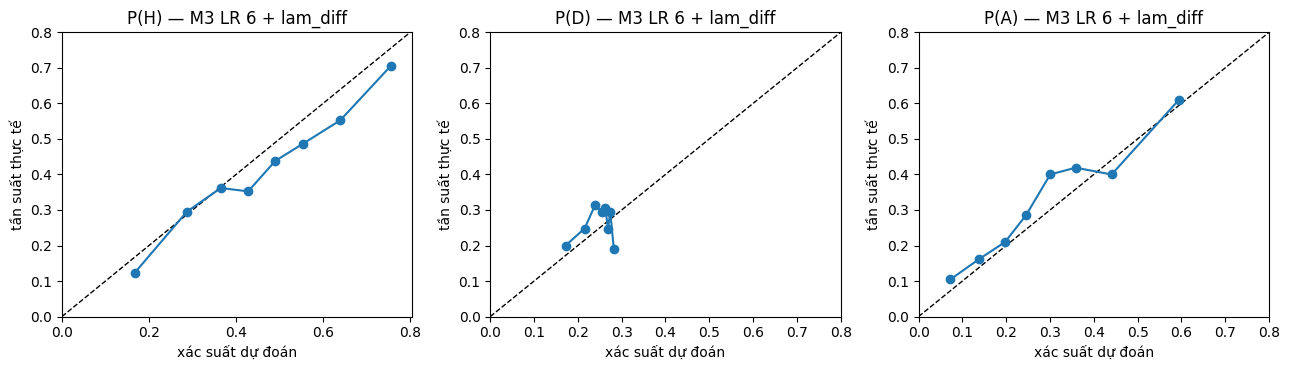

Hệ số Logistic Regression (mỗi độ lệch chuẩn của đặc trưng):
                     coef_A  coef_D  coef_H
elo_diff             -0.335   0.042   0.293
diff_points5          0.077   0.022  -0.099
diff_goals_for5      -0.030  -0.021   0.051
diff_goals_against5   0.042   0.031  -0.073
diff_ppg             -0.020  -0.029   0.048
position_diff        -0.078  -0.019   0.097
lam_diff             -0.272  -0.023   0.295


In [ ]:
# Biểu đồ hiệu chỉnh xác suất (reliability) trên Test
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
Y = onehot(test_s.result)
for k, ax in enumerate(axes):
    p = P_final_test[:, k]
    bins = np.quantile(p, np.linspace(0, 1, 9)); bins[-1] += 1e-9
    b = np.digitize(p, bins[1:-1])
    xs = [p[b == i].mean() for i in range(8) if (b == i).any()]
    ys = [Y[b == i, k].mean() for i in range(8) if (b == i).any()]
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.plot(xs, ys, 'o-')
    ax.set_title(f'P({RESULT_ORDER[k]}) — {FINAL_NAME}'); ax.set_xlabel('xác suất dự đoán'); ax.set_ylabel('tần suất thực tế')
    ax.set_xlim(0, max(0.8, max(xs) + .05)); ax.set_ylim(0, max(0.8, max(ys) + .05))
plt.tight_layout(); plt.show()

# Hệ số LR (đã chuẩn hoá) — dễ giải thích trước giám khảo
_, lr_model = fit_predict(SPECS[REF_NAME], trdev_s, test_s.head(1), RHO_EVAL)
coef = pd.DataFrame(lr_model.named_steps['lr'].coef_.T, index=SPECS[REF_NAME]['feats'],
                    columns=[f'coef_{c}' for c in lr_model.classes_])
print('Hệ số Logistic Regression (mỗi độ lệch chuẩn của đặc trưng):'); print(coef.round(3).to_string())

## 10b. Thử nghiệm: thêm kèo nhà cái (odds)
Cell này **chỉ để thử nghiệm**, không thay đổi mô hình đã chọn hay file dự đoán.
Nếu `USE_ODDS_FEATURE = True` thì "Mô hình cuối" đã có odds sẵn; nếu `False` thì đây là cách xem odds giúp được bao nhiêu mà không đổi mô hình chính.

So sánh trên **cùng các trận Test có odds**:
- **Mô hình cuối** (không odds) · **Nhà cái** (xác suất odds đã chuẩn hóa, bỏ overround)
- **LR + odds**: LR 6 cột + `lam_diff` + 2 đặc trưng từ odds: `log(pH/pA)` và `log(pD)`; `C` chọn trên Dev
- **Blend**: w · mô hình + (1 − w) · nhà cái; `w` chọn trên Dev

Δ = log loss(mô hình) − log loss(nhà cái): âm nghĩa là mô hình tốt hơn nhà cái.

In [ ]:
if ODDS_COLS is None:
    print('Không có cột odds → bỏ qua thử nghiệm này.')
else:
    def add_odds_feats(d):
        d = d.copy()
        P = bookie_probs(d)
        d['bk_H'], d['bk_D'], d['bk_A'] = P[:, 0], P[:, 1], P[:, 2]
        with np.errstate(divide='ignore', invalid='ignore'):
            d['odds_logit_ha'] = np.log(d['bk_H'] / d['bk_A'])
            d['odds_log_d'] = np.log(d['bk_D'])
        d['has_odds'] = np.isfinite(P).all(1) & (P > 0).all(1)
        return d

    tr_o, dev_o, trdev_o, test_o = (add_odds_feats(d) for d in (tr_s, dev_s, trdev_s, test_s))
    for name, d in [('train', tr_o), ('dev', dev_o), ('test', test_o)]:
        print(f'{name:5s}: {d.has_odds.mean():.1%} trận có odds ({d.has_odds.sum()}/{len(d)})')

    LR_ODDS = list(dict.fromkeys(LR_BASE + ['lam_diff'] + ['odds_logit_ha', 'odds_log_d']))
    tr_ok, dev_ok = tr_o[tr_o.has_odds], dev_o[dev_o.has_odds]
    dev_mask = dev_o.has_odds.values

    # --- Chọn C cho LR + odds trên Dev ---
    c_rows = []
    for C in C_GRID:
        P, _ = fit_predict({'kind': 'lr', 'feats': LR_ODDS, 'C': C}, tr_ok, dev_ok, RHO_SEL)
        c_rows.append((C, float(ll_vec(P, dev_ok.result).mean())))
    C_ODDS = min(c_rows, key=lambda r: r[1])[0]
    print('\nLR + odds — log loss Dev theo C:', {c: round(v, 4) for c, v in c_rows}, '→ C =', C_ODDS)

    # --- Chọn w cho Blend (mô hình cuối + nhà cái) trên Dev ---
    P_dev_model = dev_preds[FINAL_NAME][dev_mask]
    P_dev_bk = dev_ok[['bk_H', 'bk_D', 'bk_A']].values
    ws_bk = np.round(np.arange(0, 1.01, 0.05), 2)
    ll_w = [ll_vec(w * P_dev_model + (1 - w) * P_dev_bk, dev_ok.result).mean() for w in ws_bk]
    W_BK = float(ws_bk[int(np.argmin(ll_w))])
    print(f'Blend — w tốt nhất trên Dev = {W_BK} (w = trọng số của mô hình, 1 − w của nhà cái)')

    # --- Đánh giá trên Test (cùng tập trận có odds) ---
    te_mask = test_o.has_odds.values
    te_ok = test_o[te_mask]
    y_te = te_ok.result.values
    P_te_model = test_preds[FINAL_NAME][te_mask]
    P_te_bk = te_ok[['bk_H', 'bk_D', 'bk_A']].values
    P_te_lro, lr_odds_model = fit_predict({'kind': 'lr', 'feats': LR_ODDS, 'C': C_ODDS},
                                          trdev_o[trdev_o.has_odds], te_ok, RHO_EVAL)
    P_te_blend = W_BK * P_te_model + (1 - W_BK) * P_te_bk

    odds_preds = {f'Mô hình cuối ({FINAL_NAME})': P_te_model,
                  'Nhà cái': P_te_bk,
                  'LR + odds': P_te_lro,
                  f'Blend mô hình × {W_BK} + nhà cái × {1 - W_BK:.2f}': P_te_blend}
    odds_board = pd.DataFrame([evaluate(P, y_te, n) for n, P in odds_preds.items()]).sort_values('log_loss')
    print(f'\n=== TEST ({len(te_ok)} trận có odds) ===')
    print(odds_board.round(4).to_string(index=False))

    # --- So với nhà cái: bootstrap CI 95% ---
    ll_bk = ll_vec(P_te_bk, y_te)
    rows = []
    for n, P in odds_preds.items():
        if n == 'Nhà cái': continue
        d, lo, hi, p = paired_bootstrap(ll_bk, ll_vec(P, y_te))
        rows.append({'mô hình': n, 'Δ so với nhà cái': d, 'CI_low': lo, 'CI_high': hi,
                     'kết luận': 'tốt hơn nhà cái' if hi < 0 else ('kém hơn nhà cái' if lo > 0 else 'tương đương nhà cái')})
    vs_bk = pd.DataFrame(rows)
    print('\nSo với nhà cái (Δ âm = tốt hơn nhà cái):')
    print(vs_bk.round(4).to_string(index=False))

    # Hệ số của LR + odds: odds lấn át các cột khác đến mức nào?
    coef_o = pd.DataFrame(lr_odds_model.named_steps['lr'].coef_.T, index=LR_ODDS,
                          columns=[f'coef_{c}' for c in lr_odds_model.classes_])
    print('\nHệ số LR + odds (đã chuẩn hóa):'); print(coef_o.round(3).to_string())

    # Mô hình cuối vs nhà cái theo mùa
    per_season = te_ok.assign(model=ll_vec(P_te_model, y_te), bookie=ll_bk) \
                      .groupby('season')[['model', 'bookie']].mean()
    per_season['chênh'] = per_season.model - per_season.bookie
    print('\nLog loss theo mùa (Test):'); print(per_season.round(4).to_string())

    odds_board.to_csv(os.path.join(OUT_DIR, 'odds_experiment_test.csv'), index=False)
    if ODDS_COLS is not None and odds_board.log_loss.min() < SUSPICIOUS_LL:
        print(' Có mô hình log loss < %.2f — kiểm tra lại cột odds (có phải odds đóng cửa sau trận?).' % SUSPICIOUS_LL)

train: 90.8% trận có odds (7510/8270)
dev  : 100.0% trận có odds (760/760)
test : 100.0% trận có odds (840/840)

LR + odds — log loss Dev theo C: {0.01: 0.9403, 0.03: 0.94, 0.1: 0.9398, 0.3: 0.9397, 1.0: 0.9396} → C = 1.0
Blend — w tốt nhất trên Dev = 0.0 (w = trọng số của mô hình, 1 − w của nhà cái)

=== TEST (840 trận có odds) ===
                               model   n  log_loss    rps  brier  accuracy
                             Nhà cái 840    0.9955 0.2016 0.5961    0.5143
Blend mô hình × 0.0 + nhà cái × 1.00 840    0.9955 0.2016 0.5961    0.5143
                           LR + odds 840    1.0017 0.2024 0.5996    0.5060
   Mô hình cuối (M3 LR 6 + lam_diff) 840    1.0118 0.2069 0.6071    0.4964

So với nhà cái (Δ âm = tốt hơn nhà cái):
                             mô hình  Δ so với nhà cái  CI_low  CI_high            kết luận
   Mô hình cuối (M3 LR 6 + lam_diff)            0.0163  0.0046   0.0281     kém hơn nhà cái
                           LR + odds            0.0062  0.0011  

## 10c. Accuracy theo năm bắt đầu tập train (2000 vs 2009)
Huấn luyện lại **cùng mô hình cuối và cùng siêu tham số**, chỉ thay mùa bắt đầu của tập train (`season_start` ≥ năm đó).
Dev/Test giữ nguyên như cũ. Dev: model học trên train; Test: model học trên train + dev (như mục 10).
Kèm log loss vì accuracy bỏ qua độ tự tin của xác suất. Sửa `START_YEARS` để thử thêm năm khác.

Mô hình: M3 LR 6 + lam_diff
train_from  start_year  n_train  acc_dev  acc_test  logloss_dev  logloss_test  rps_test
   2000/01        2000     8270   0.5553    0.4964       0.9526        1.0118    0.2069
   2009/10        2009     4940   0.5513    0.4964       0.9507        1.0097    0.2060

Mốc "luôn đoán đội nhà thắng": Dev 0.472 | Test 0.414


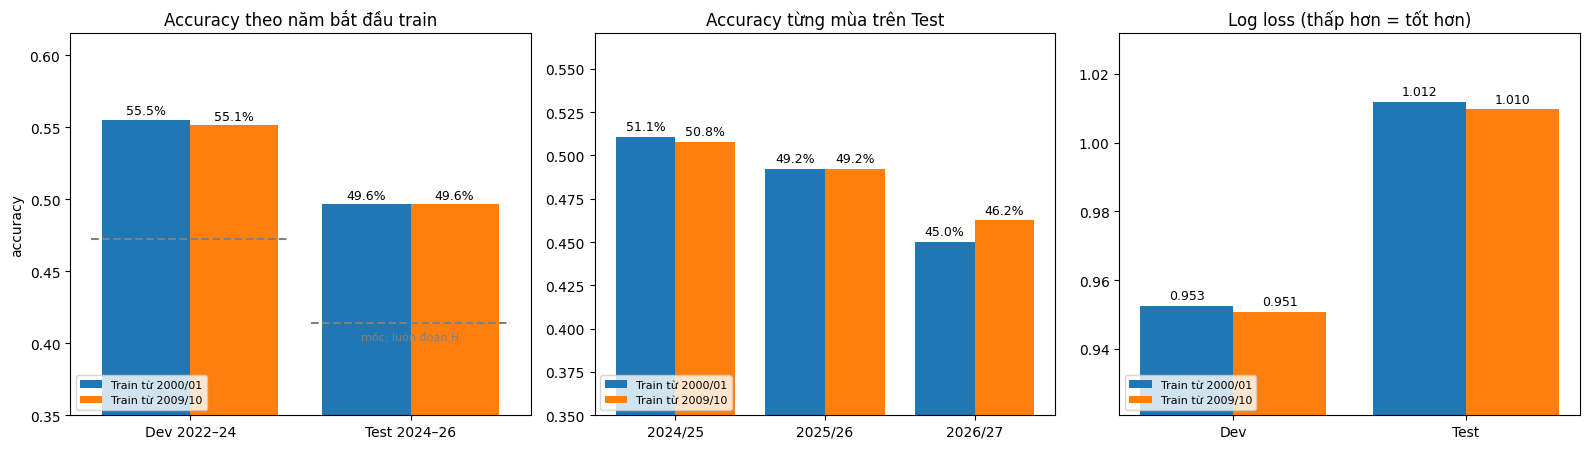

Test: accuracy(train từ 2009) − accuracy(train từ 2000) = -0.000%  CI95% [-0.595%, +0.595%]
→ CI chứa 0: khác biệt chưa có ý nghĩa thống kê.


In [ ]:
START_YEARS = [2000, 2009]          # năm bắt đầu tập train (season_start)

acc_rows, season_rows = [], []
for sy in START_YEARS:
    tr_y = train[train.season_start >= sy]
    # Dev: học trên train (từ sy)
    tr_y_s, (dev_y_s,), _, rho_y = prepare_stage(tr_y, [dev], BEST_ALPHA)
    P_dev_y, _ = fit_predict(FINAL_SPEC, tr_y_s, dev_y_s, rho_y)
    # Test: học trên train (từ sy) + dev
    trdev_y_s, (test_y_s,), _, rho_y2 = prepare_stage(pd.concat([tr_y, dev]), [test], BEST_ALPHA)
    P_test_y, _ = fit_predict(FINAL_SPEC, trdev_y_s, test_y_s, rho_y2)

    ev_dev, ev_test = evaluate(P_dev_y, dev_y_s.result), evaluate(P_test_y, test_y_s.result)
    acc_rows.append({'train_from': f'{sy}/{str(sy + 1)[2:]}', 'start_year': sy, 'n_train': len(tr_y),
                     'acc_dev': ev_dev['accuracy'], 'acc_test': ev_test['accuracy'],
                     'logloss_dev': ev_dev['log_loss'], 'logloss_test': ev_test['log_loss'],
                     'rps_test': ev_test['rps']})
    hit = np.array(RESULT_ORDER)[P_test_y.argmax(1)] == test_y_s.result.values
    for season, g in test_y_s.assign(hit=hit).groupby('season'):
        season_rows.append({'start_year': sy, 'season': season, 'accuracy': g.hit.mean(), 'n': len(g)})

acc_tab = pd.DataFrame(acc_rows)
season_tab = pd.DataFrame(season_rows)
always_H_dev, always_H_test = (dev.result == 'H').mean(), (test.result == 'H').mean()
print(f'Mô hình: {FINAL_NAME}')
print(acc_tab.round(4).to_string(index=False))
print(f'\nMốc "luôn đoán đội nhà thắng": Dev {always_H_dev:.3f} | Test {always_H_test:.3f}')

# ---------------- Biểu đồ ----------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
labels = [f'Train từ {r}' for r in acc_tab.train_from]
colors = plt.cm.tab10.colors

# (1) Accuracy Dev & Test
ax = axes[0]; x = np.arange(2); w = 0.8 / len(acc_tab)
for k, r in acc_tab.iterrows():
    vals = [r.acc_dev, r.acc_test]
    bars = ax.bar(x + (k - (len(acc_tab) - 1) / 2) * w, vals, w, label=labels[k], color=colors[k])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f'{v:.1%}', ha='center', fontsize=9)
for xi, base in zip(x, [always_H_dev, always_H_test]):
    ax.hlines(base, xi - 0.45, xi + 0.45, colors='grey', linestyles='--')
ax.text(1, always_H_test - 0.012, 'mốc: luôn đoán H', ha='center', fontsize=8, color='grey')
ax.set_xticks(x); ax.set_xticklabels(['Dev 2022–24', 'Test 2024–26'])
ax.set_ylim(0.35, max(acc_tab[['acc_dev', 'acc_test']].max()) + 0.06)
ax.set_ylabel('accuracy'); ax.set_title('Accuracy theo năm bắt đầu train'); ax.legend(fontsize=8, loc='lower left')

# (2) Accuracy từng mùa của Test
ax = axes[1]; seasons = sorted(season_tab.season.unique()); xs = np.arange(len(seasons))
for k, sy in enumerate(START_YEARS):
    g = season_tab[season_tab.start_year == sy].set_index('season').reindex(seasons)
    bars = ax.bar(xs + (k - (len(START_YEARS) - 1) / 2) * w, g.accuracy, w, label=labels[k], color=colors[k])
    for b, v in zip(bars, g.accuracy):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f'{v:.1%}', ha='center', fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(seasons); ax.set_ylim(0.35, season_tab.accuracy.max() + 0.06)
ax.set_title('Accuracy từng mùa trên Test'); ax.legend(fontsize=8, loc='lower left')

# (3) Log loss (thấp hơn = tốt hơn) để đối chiếu
ax = axes[2]
for k, r in acc_tab.iterrows():
    vals = [r.logloss_dev, r.logloss_test]
    bars = ax.bar(x + (k - (len(acc_tab) - 1) / 2) * w, vals, w, label=labels[k], color=colors[k])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f'{v:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Dev', 'Test'])
lo = acc_tab[['logloss_dev', 'logloss_test']].values.min(); hi = acc_tab[['logloss_dev', 'logloss_test']].values.max()
ax.set_ylim(lo - 0.03, hi + 0.02); ax.set_title('Log loss (thấp hơn = tốt hơn)'); ax.legend(fontsize=8, loc='lower left')

plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'accuracy_by_train_start.png'), dpi=150, bbox_inches='tight')
plt.show()

acc_tab.to_csv(os.path.join(OUT_DIR, 'accuracy_by_train_start.csv'), index=False)
season_tab.to_csv(os.path.join(OUT_DIR, 'accuracy_by_train_start_per_season.csv'), index=False)

# Chênh lệch có ý nghĩa không? (bootstrap trên Test, 2 năm đầu tiên trong danh sách)
if len(START_YEARS) >= 2:
    hits = {}
    for sy in START_YEARS[:2]:
        tr_y = train[train.season_start >= sy]
        trdev_y_s, (test_y_s,), _, rho_y2 = prepare_stage(pd.concat([tr_y, dev]), [test], BEST_ALPHA)
        P, _ = fit_predict(FINAL_SPEC, trdev_y_s, test_y_s, rho_y2)
        hits[sy] = (np.array(RESULT_ORDER)[P.argmax(1)] == test_y_s.result.values).astype(float)
    a, b = START_YEARS[:2]
    d, lo_, hi_, _ = paired_bootstrap(1 - hits[a], 1 - hits[b])   # Δ sai số: âm = train từ b tốt hơn
    print(f'Test: accuracy(train từ {b}) − accuracy(train từ {a}) = {-d:+.3%}  CI95% [{-hi_:+.3%}, {-lo_:+.3%}]')
    print('→ CI chứa 0: khác biệt chưa có ý nghĩa thống kê.' if lo_ < 0 < hi_ else '→ Khác biệt có ý nghĩa thống kê.')

## 11. Nhiệm vụ 4 — Xuất dự đoán: `predictions_test.csv` (tập test) và `predictions.csv` (trận sắp đá, nếu có)
`pred_home_goals`, `pred_away_goals` = tỉ số có xác suất cao nhất **trong vùng khớp với `pred_result`** (H: nhà > khách, D: bằng nhau, A: nhà < khách).
`likeliest_score` = tỉ số có xác suất cao nhất trên toàn ma trận (có thể khác kết quả dự đoán, thường là 1-1).

In [ ]:
def score_table(M, P):
    pred_result = np.array(RESULT_ORDER)[P.argmax(1)]
    phg, pag, likeliest = [], [], []
    for n in range(len(M)):
        masked = np.where(REGION[pred_result[n]], M[n], -1)
        i, j = np.unravel_index(masked.argmax(), masked.shape); phg.append(i); pag.append(j)
        gi, gj = np.unravel_index(M[n].argmax(), M[n].shape); likeliest.append(f'{gi}-{gj}')
    return pred_result, phg, pag, likeliest

ID_OUT = [c for c in ['match_id', 'season', 'date', 'gameweek', 'home_team', 'away_team'] if c in df.columns]

# (a) Dự đoán trên tập TEST (mô hình huấn luyện trên train+dev) — dùng để báo cáo / so với kết quả thật
r, phg, pag, lk = score_table(M_test, P_final_test)
pt = test_s[ID_OUT].copy()
pt['p_home'], pt['p_draw'], pt['p_away'] = P_final_test.round(4).T
pt['pred_result'], pt['pred_home_goals'], pt['pred_away_goals'], pt['likeliest_score'] = r, phg, pag, lk
pt['exp_home_goals'], pt['exp_away_goals'] = test_s.lam_h.round(2).values, test_s.lam_a.round(2).values
pt['true_result'] = test_s.result.values
pt['true_score'] = test_s.home_goals.astype(int).astype(str).values + '-' + test_s.away_goals.astype(int).astype(str).values
pt.to_csv(os.path.join(OUT_DIR, 'predictions_test.csv'), index=False)
print('Đã ghi predictions_test.csv |', f"đúng H/D/A: {(pt.pred_result == pt.true_result).mean():.3f}",
      f"| đúng tỉ số (pred): {(pt.pred_home_goals.astype(str) + '-' + pt.pred_away_goals.astype(str) == pt.true_score).mean():.3f}")
print(pt.head(10).to_string(index=False))

# (b) Trận sắp đá (status = upcoming)
if len(upcoming) == 0:
    print('\nfeatures.csv hiện không có trận upcoming (mọi trận đều đã đá).')
    print('Khi pipeline tạo đặc trưng cho mùa 2026/27 (folder 2026_2027_new/), chạy lại ô này để ghi predictions.csv.')
else:
    if ODDS_FEATS and upcoming['odds_missing'].mean() > 0:
        print(f"{int(upcoming['odds_missing'].sum())} trận sắp đá chưa có odds → odds bị điền trung vị, dự đoán các trận này kém tin cậy hơn.")
    prod_train = played_all if REFIT_WITH_TEST_FOR_PRODUCTION else trdev
    prod_s, (up_s,), poi_models_prod, RHO_PROD = prepare_stage(prod_train, [upcoming], BEST_ALPHA)
    P_up, final_model = fit_predict(FINAL_SPEC, prod_s, up_s, RHO_PROD)
    M_up = score_matrix(up_s.lam_h, up_s.lam_a, RHO_PROD)

    pred_result, phg, pag, likeliest = score_table(M_up, P_up)
    pred = up_s[ID_OUT].copy()
    pred['p_home'], pred['p_draw'], pred['p_away'] = P_up[:, 0].round(4), P_up[:, 1].round(4), P_up[:, 2].round(4)
    pred['pred_result'] = pred_result
    pred['pred_home_goals'], pred['pred_away_goals'] = phg, pag
    pred['likeliest_score'] = likeliest
    pred['exp_home_goals'], pred['exp_away_goals'] = up_s.lam_h.round(2).values, up_s.lam_a.round(2).values
    pred['model'] = FINAL_NAME

    out_path = os.path.join(OUT_DIR, 'predictions.csv')
    pred.to_csv(out_path, index=False)
    print('Đã ghi', out_path, '| dữ liệu huấn luyện:', 'tất cả trận đã đá' if REFIT_WITH_TEST_FOR_PRODUCTION else 'train+dev')
    print(pred.head(20).to_string(index=False))

    joblib.dump({'final_spec': FINAL_SPEC, 'final_model': final_model, 'poisson_models': poi_models_prod,
                 'rho': RHO_PROD, 'alpha': BEST_ALPHA, 'poi_feats': POI_FEATS, 'result_order': RESULT_ORDER},
                os.path.join(OUT_DIR, 'final_models.joblib'))
print('\nFile trong', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

Đã ghi predictions_test.csv | đúng H/D/A: 0.496 | đúng tỉ số (pred): 0.085
             match_id  season       date  gameweek         home_team       away_team  p_home  p_draw  p_away pred_result  pred_home_goals  pred_away_goals likeliest_score  exp_home_goals  exp_away_goals true_result true_score
EPL_2024_2025_MUN_FUL 2024/25 2024-08-16       NaN Manchester United          Fulham  0.5427  0.2531  0.2041           H                1                0             1-1            1.64            1.03           H        1-0
EPL_2024_2025_IPS_LIV 2024/25 2024-08-17       NaN           Ipswich       Liverpool  0.2100  0.2593  0.5307           A                0                1             1-1            1.04            1.58           A        0-2
EPL_2024_2025_ARS_WOL 2024/25 2024-08-17       NaN           Arsenal          Wolves  0.8199  0.1356  0.0445           H                2                0             2-0            2.69            0.61           H        2-0
EPL_2024_2025_EVE_BHA

## 12. Tổng kết file kết quả

In [ ]:
import json, shutil
# Lưu cấu hình + lựa chọn của lần chạy để sau này biết file nào ra từ thiết lập nào
run_info = {
    'run_name': RUN_NAME, 'colab': IN_COLAB, 'features_csv': FEATURES_CSV,
    'train_seasons': f'{TRAIN_START}/{TRAIN_START+1} → {TRAIN_END}/{TRAIN_END+1}',
    'dev_seasons': f'{DEV_START}/{DEV_START+1} → {DEV_END}/{DEV_END+1}',
    'test_from': f'{TEST_START}/{TEST_START+1}',
    'use_odds_feature': bool(ODDS_FEATS), 'odds_feats': ODDS_FEATS,
    'poisson_alpha': BEST_ALPHA, 'rho_dixon_coles_eval': float(RHO_EVAL),
    'C_6cols': C6, 'C_6cols_lam': C7, 'final_model': FINAL_NAME,
    'test_log_loss_final': float(test_board.set_index('model').loc[FINAL_NAME, 'log_loss']),
}
with open(os.path.join(OUT_DIR, 'run_info.json'), 'w', encoding='utf-8') as f:
    json.dump(run_info, f, ensure_ascii=False, indent=2)

print('Folder kết quả:', OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print(f'   {name:32s} {os.path.getsize(os.path.join(OUT_DIR, name)) / 1024:8.1f} KB')

# Nén cả folder thành 1 file .zip để tải về một lần
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print('\n🗜️  File nén:', zip_path)
print('   Mở Google Drive → epl_ml_outputs để xem hoặc tải về.')

Folder kết quả: /content/drive/MyDrive/epl_ml_outputs/run_20261111_0227_no_odds
   accuracy_by_train_start.csv           0.3 KB
   accuracy_by_train_start.png          92.8 KB
   accuracy_by_train_start_per_season.csv      0.2 KB
   hypothesis_tests.csv                  2.0 KB
   odds_experiment_test.csv              0.4 KB
   predictions_test.csv                 90.5 KB
   run_info.json                         0.5 KB
   test_metrics.csv                      0.6 KB

🗜️  File nén: /content/drive/MyDrive/epl_ml_outputs/run_20261111_0227_no_odds.zip
   Mở Google Drive → epl_ml_outputs để xem hoặc tải về.


## Ghi chú diễn giải
- **Chọn mô hình chỉ bằng Dev**; Test được dùng đúng một lần ở mục 10. Nếu sau khi xem Test bạn quay lại sửa mô hình, điểm Test không còn khách quan.
- Nếu M5/M6/M7 chỉ hơn M3 rất ít và CI chứa 0, nên báo cáo M3 (đúng PDF) là mô hình chính và trình bày phần nâng cấp như thí nghiệm bổ sung.
- Mùa 2019/20 – 2020/21 (COVID, không khán giả) làm lợi thế sân nhà giảm mạnh — đây là lý do H5 (`league_home_adv380`) đáng kiểm định.
- Log loss của đoán theo tần suất thường khoảng 1,06–1,07; nhà cái thường khoảng 0,95–0,97 trên EPL. Mô hình không dùng odds đạt quanh 0,95–0,97 là hợp lý.